# DECANT + PCA on the Tian_A5A7 methylation dataset

DECANT feature selection (10,000 regions) followed by a PCA embedding on the Tian A5-A7 scDNAm dataset, then evaluation with the six integration metrics and the Overall score.

Download the two raw Tian A5-A7 files (GEO GSE179129 and GSE179610) from [Google Drive](https://drive.google.com/drive/folders/1gQBjm_2TH0Ozjg_jO_7rwSgeKNp8emVh?usp=sharing) and point `RAW_GSE179129` and `RAW_GSE179610` at them.

## Setup

In [1]:
import scanpy as sc
import pandas as pd
from decant.core import run_decant, run_pca
from decant.metrics import evaluate_metrics, calc_overall

RAW_GSE179129 = "../data/raw/GSE179129.h5ad"
RAW_GSE179610 = "../data/raw/GSE179610.h5ad"
PROCESSED_A5A7 = "../data/tian_a5a7.h5ad"
PREPROCESS_OUT = "../data/processed/tian_a5a7_preprocess"
DATA_PATH = PROCESSED_A5A7
OMICS = "meth"
BATCH_KEY = "batch"
LABEL_KEY = "MajorType"
N_FEATURES = 10000
SEED = 0

## Data preprocessing

The two raw donor files are paired into one methylation matrix with `preprocess_pair_scdnam_h5ad()` (shared cell types kept, missing bins median-filled) and written to `data/tian_a5a7.h5ad`.

In [2]:
from decant.preprocess import preprocess_pair_scdnam_h5ad

manifest = preprocess_pair_scdnam_h5ad(
    input_h5ads=[RAW_GSE179129, RAW_GSE179610],
    output_dir=PREPROCESS_OUT,
    output_filenames=[
        "Tian-A5-A7-GSE179129_MajorType.h5ad",
        "Tian-A5-A7-GSE179610_MajorType.h5ad",
    ],
    target_col="MajorType",
    batch_labels=("GSE179129", "GSE179610"),
    filter_rule="filtered_intersection_gt10",
    write_combined_h5ad=PROCESSED_A5A7,
    rebuild_windows=False,
    overwrite=False,
)

## Load the preprocessed data

In [3]:
adata = sc.read_h5ad(DATA_PATH)
batch_names = sorted(adata.obs[BATCH_KEY].astype(str).unique())
adata.obs[BATCH_KEY] = adata.obs[BATCH_KEY].astype(str).map(
    {name: f"batch{i + 1}" for i, name in enumerate(batch_names)}).astype("category")
adata.obs[LABEL_KEY] = adata.obs[LABEL_KEY].astype(str).astype("category")
adata

AnnData object with n_obs × n_vars = 5332 × 293836
    obs: 'mCCCFrac', 'mCGFrac', 'mCHFrac', 'FinalmCReads', 'pool', 'Donor #', 'Region', 'tech', 'SubType_index', 'SubType', 'MajorType', 'CellClass', 'Note', 'batch', 'data_batch'
    uns: 'preprocess_note', 'target_col'

## Visualize before DECANT (all features)

UMAP of a PCA embedding built from all preprocessed features, before DECANT selects any. Colour by batch and cell type, then compare with the after-DECANT UMAP.

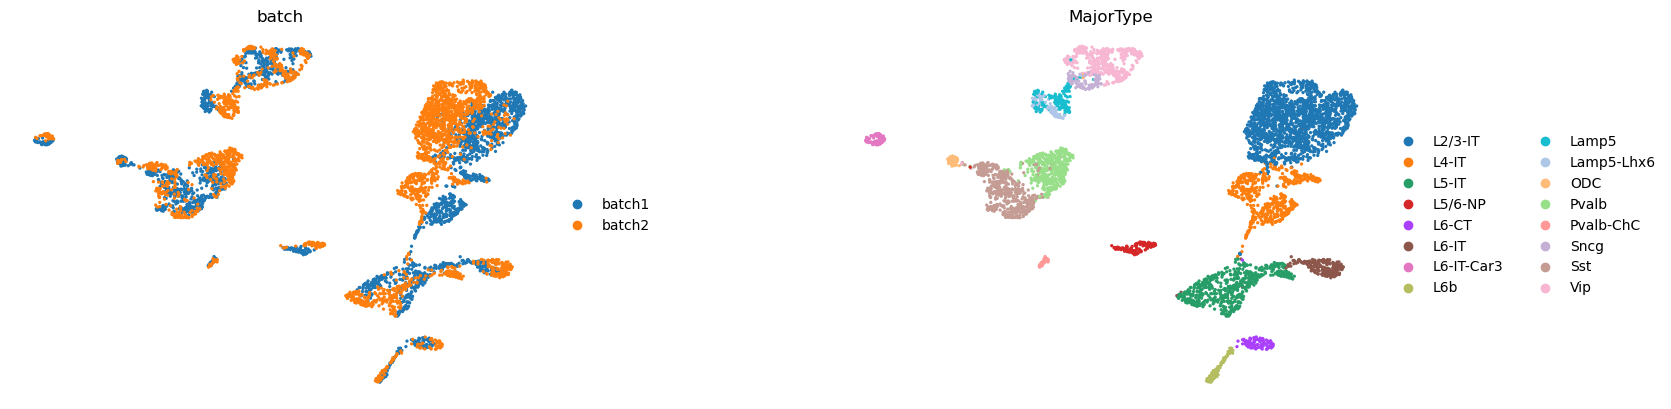

In [4]:
before, _ = run_pca(adata, OMICS, seed=SEED)
sc.pp.neighbors(before, use_rep="X_pca", n_neighbors=15, random_state=SEED)
sc.tl.umap(before, random_state=SEED)
sc.pl.umap(before, color=[BATCH_KEY, LABEL_KEY], wspace=0.4, frameon=False)


## DECANT feature selection

DECANT is label-free: it ranks features and selects the gamma with the highest tuning score.

In [5]:
result = run_decant(adata, omics=OMICS, batch_key=BATCH_KEY,
                    n_features=N_FEATURES, seed=SEED)
print(f"Selected {result['n_features']} features")


Selected 10000 features


The DECANT process is expected to take approximately 10-20 minutes.

## Evaluate integration

This step is downstream of feature selection: it benchmarks the DECANT embedding with the six integration metrics and the Overall score.

In [6]:
from IPython.utils.capture import capture_output

with capture_output(stdout=True, stderr=False, display=False):
    metrics = evaluate_metrics(result["embedding"], "X_pca", BATCH_KEY, LABEL_KEY)
metrics["Overall"] = calc_overall(metrics, result["n_batches"])
pd.Series(metrics).round(4)

AMI                   0.8467
ARI                   0.5795
NMI                   0.8484
batchASW              0.9414
Graph_connectivity    0.9981
iLISI                 1.8027
Overall               0.8206
dtype: float64

## Visualize after DECANT (selected features)

UMAP of the DECANT embedding (PCA on the selected features). Same pipeline as the before-DECANT UMAP above, only the feature set differs.

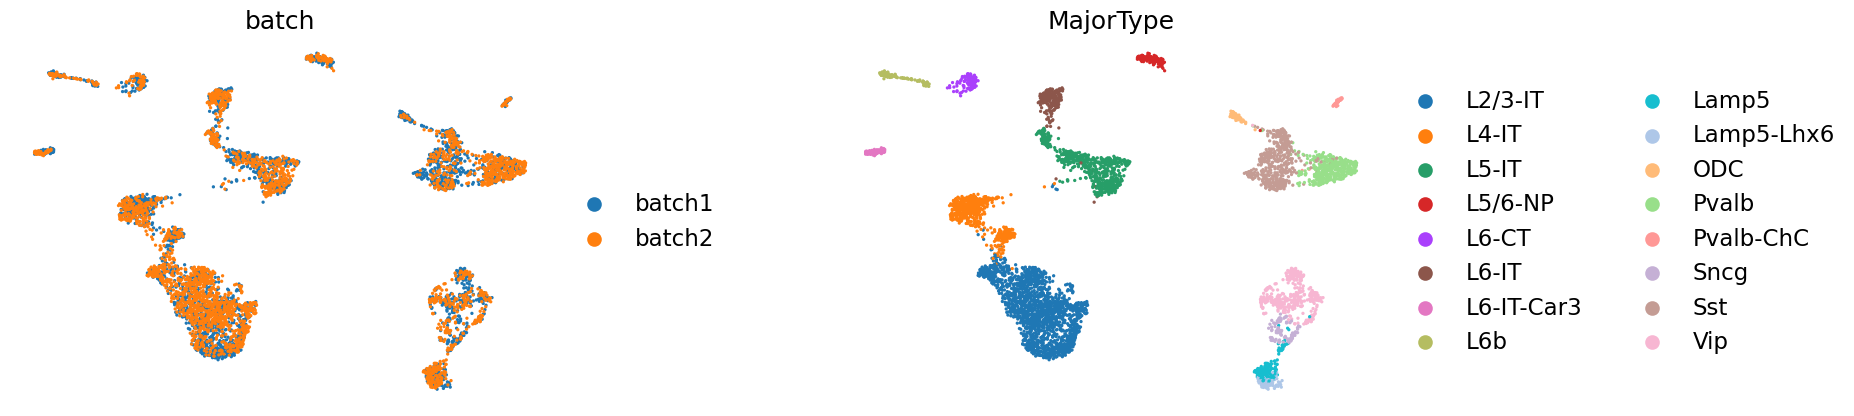

In [7]:
emb = result["embedding"]
sc.pp.neighbors(emb, use_rep="X_pca", n_neighbors=15, random_state=SEED)
sc.tl.umap(emb, random_state=SEED)
sc.pl.umap(emb, color=[BATCH_KEY, LABEL_KEY], wspace=0.4, frameon=False)
